# Network Performance Analysis

**Goal:** turn raw, time-stamped network records into KPIs, SQL summaries and charts that could support monitoring and troubleshooting.

**Data:** `data/simulated_network_data.csv` - 330 simulated observations from 5 nodes (101-105) over 2026-01-01 to 2026-01-15. The data is *simulated* (see `generate_simulated_data.ipynb`); it is not from a live network.

**Workflow:** load CSV -> store in SQLite -> validate and flag -> SQL summaries -> KPI table -> statistical tests -> charts.

In [ ]:
from pathlib import Path
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configuration 
LATENCY_SLA_MS = 75      # illustrative: latency above this counts as a breach
RESPONSE_SLA_MS = 400    # illustrative: response time above this counts as slow

# Locate the data whether we run from the repo root, notebooks/, or Colab
CANDIDATES = [
    Path("../data/simulated_network_data.csv"),
    Path("data/simulated_network_data.csv"),
    Path("simulated_network_data.csv"),
]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("simulated_network_data.csv not found - check the path.")

ROOT = DATA_PATH.resolve().parent.parent if DATA_PATH.parent.name == "data" else DATA_PATH.resolve().parent
IMAGES_DIR = ROOT / "images"
IMAGES_DIR.mkdir(exist_ok=True)
DB_PATH = DATA_PATH.resolve().parent / "network_data.db"   # recreated each run, git-ignored


# Chart style 
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "font.size": 10.5,
})

def save_fig(fig, name):
    fig.savefig(IMAGES_DIR / name, dpi=150, bbox_inches="tight")

print(f"Data file : {DATA_PATH}")
print(f"Charts to : {IMAGES_DIR}")

Data file : ..\data\simulated_network_data.csv
Charts to : C:\Users\Dellia\Documents\Python\network-data-analysis\images


## 1. Load the data into SQLite

The CSV is written to a SQLite table (`network_traffic`) and read back with SQL.

In [3]:
df_raw = pd.read_csv(DATA_PATH)

conn = sqlite3.connect(DB_PATH)
df_raw.to_sql("network_traffic", conn, if_exists="replace", index=False)

df = pd.read_sql("SELECT * FROM network_traffic;", conn)
print(f"Loaded {len(df)} rows into table 'network_traffic'.")
df.head()

Loaded 330 rows into table 'network_traffic'.


,timestamp,node_id,latency_ms,response_time_ms,throughput_MBps,status
0,2026-01-01 01:47:00,102,65.91,135.07,2.55,Active
1,2026-01-01 02:43:00,103,53.56,62.77,7.37,Active
2,2026-01-01 04:20:00,104,45.24,170.60,2.84,Active
3,2026-01-01 04:39:00,102,56.88,277.18,3.17,Active
4,2026-01-01 06:30:00,101,52.79,483.79,3.47,Inactive


## 2. Inspect the data

`node_id` is an identifier, not a quantity, so it is left out of the numeric summary (an "average node ID" is meaningless).

In [4]:
MEASURES = ["latency_ms", "response_time_ms", "throughput_MBps"]
ts = pd.to_datetime(df["timestamp"])

print(f"Rows: {len(df)} | Columns: {df.shape[1]}")
print(f"Missing values: {int(df.isnull().sum().sum())} | Duplicate rows: {int(df.duplicated().sum())}")
print(f"Nodes: {sorted(int(n) for n in df['node_id'].unique())}")
print(f"Status values: {sorted(df['status'].unique())}")
print(f"Period: {ts.min()} -> {ts.max()} | sorted by time: {ts.is_monotonic_increasing}")

gaps = ts.diff().dt.total_seconds().div(60).dropna()
print(f"Gap between observations (minutes): min {gaps.min():.0f}, median {gaps.median():.0f}, max {gaps.max():.0f}")

df[MEASURES].describe().round(2)

Rows: 330 | Columns: 6
Missing values: 0 | Duplicate rows: 0
Nodes: [101, 102, 103, 104, 105]
Status values: ['Active', 'Error', 'Inactive']
Period: 2026-01-01 01:47:00 -> 2026-01-15 08:14:00 | sorted by time: True
Gap between observations (minutes): min 5, median 64, max 120


,latency_ms,response_time_ms,throughput_MBps
count,330.00,330.00,330.00
mean,50.87,180.20,4.91
std,16.33,87.19,1.52
min,5.00,42.15,0.10
25%,40.19,115.96,3.90
50%,51.86,162.94,4.90
75%,61.44,225.13,6.00
max,97.62,507.23,8.94


## 3. Validate and flag (instead of deleting)

1. **Validate** - remove only records that are physically impossible or malformed (bad timestamps, negative values, unknown status labels, a response time smaller than its own latency).
2. **Flag** - keep every plausible record and add breach flags (`latency_breach`, `response_breach`) using the configurable thresholds.

In [5]:
df_clean = df.copy()
df_clean["timestamp"] = pd.to_datetime(df_clean["timestamp"], errors="coerce")

valid_status = ["Active", "Inactive", "Error"]
problems = {
    "invalid timestamps":                  df_clean["timestamp"].isna(),
    "latency <= 0 or > 150 ms":            ~df_clean["latency_ms"].between(0, 150, inclusive="right"),
    "response time smaller than latency":  df_clean["response_time_ms"] < df_clean["latency_ms"],
    "throughput <= 0":                     df_clean["throughput_MBps"] <= 0,
    "unknown status label":                ~df_clean["status"].isin(valid_status),
}
for name, mask in problems.items():
    print(f"{name:38s}: {int(mask.sum())}")

invalid = pd.concat(problems.values(), axis=1).any(axis=1)
df_clean = df_clean.loc[~invalid].copy()
print(f"\nRows removed as invalid: {int(invalid.sum())} | rows kept: {len(df_clean)}")

# Derived fields and breach flags
df_clean["date"] = df_clean["timestamp"].dt.strftime("%Y-%m-%d")
df_clean["hour"] = df_clean["timestamp"].dt.hour
df_clean["latency_breach"] = (df_clean["latency_ms"] > LATENCY_SLA_MS).astype(int)
df_clean["response_breach"] = (df_clean["response_time_ms"] > RESPONSE_SLA_MS).astype(int)

print(f"\nLatency > {LATENCY_SLA_MS} ms   : {df_clean['latency_breach'].sum()} rows ({df_clean['latency_breach'].mean():.1%})")
print(f"Response > {RESPONSE_SLA_MS} ms : {df_clean['response_breach'].sum()} rows ({df_clean['response_breach'].mean():.1%})")

df_clean.to_sql("cleaned_network_traffic", conn, if_exists="replace", index=False)
print("\nSaved to table 'cleaned_network_traffic'.")

invalid timestamps                    : 0
latency <= 0 or > 150 ms              : 0
response time smaller than latency    : 0
throughput <= 0                       : 0
unknown status label                  : 0

Rows removed as invalid: 0 | rows kept: 330

Latency > 75 ms   : 25 rows (7.6%)
Response > 400 ms : 10 rows (3.0%)

Saved to table 'cleaned_network_traffic'.


## 4. SQL analysis

All aggregations below are done in SQL against the cleaned table.

In [6]:
# Per-node summary: volume, averages, availability, errors, slow responses
node_query = """
SELECT
    node_id,
    COUNT(*)                                              AS observations,
    ROUND(AVG(latency_ms), 2)                             AS avg_latency_ms,
    ROUND(AVG(response_time_ms), 2)                       AS avg_response_ms,
    ROUND(AVG(throughput_MBps), 2)                        AS avg_throughput_MBps,
    ROUND(100.0 * SUM(status = 'Active') / COUNT(*), 1)   AS availability_pct,
    ROUND(100.0 * SUM(status = 'Error')  / COUNT(*), 1)   AS error_rate_pct,
    SUM(response_breach)                                  AS slow_responses
FROM cleaned_network_traffic
GROUP BY node_id
ORDER BY node_id;
"""
node_summary = pd.read_sql_query(node_query, conn)
node_summary

,node_id,observations,avg_latency_ms,avg_response_ms,avg_throughput_MBps,availability_pct,error_rate_pct,slow_responses
0,101,68,50.47,189.15,4.77,88.2,4.4,3
1,102,67,51.85,173.34,4.80,85.1,4.5,2
2,103,57,47.99,168.86,4.79,80.7,3.5,1
3,104,67,51.47,176.62,5.22,86.6,7.5,1
4,105,71,52.09,190.56,4.96,84.5,8.5,3


In [7]:
# Network status distribution
status_query = """
SELECT
    status,
    COUNT(*) AS record_count,
    ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM cleaned_network_traffic), 2) AS percentage
FROM cleaned_network_traffic
GROUP BY status
ORDER BY record_count DESC;
"""
status_summary = pd.read_sql_query(status_query, conn)
status_summary

,status,record_count,percentage
0,Active,281,85.15
1,Inactive,30,9.09
2,Error,19,5.76


In [8]:
# Daily average latency (first and last days are partial: data starts 01:47 on Jan 1 and ends 08:14 on Jan 15)
daily_query = """
SELECT
    DATE(timestamp)            AS observation_date,
    COUNT(*)                   AS observations,
    ROUND(AVG(latency_ms), 2)  AS daily_latency_ms
FROM cleaned_network_traffic
GROUP BY DATE(timestamp)
ORDER BY observation_date;
"""
daily_latency = pd.read_sql_query(daily_query, conn)
daily_latency

,observation_date,observations,daily_latency_ms
0,2026-01-01,21,49.55
1,2026-01-02,23,45.44
2,2026-01-03,25,47.94
3,2026-01-04,24,51.31
4,2026-01-05,21,57.07
5,2026-01-06,25,52.56
6,2026-01-07,24,49.69
7,2026-01-08,23,49.49
8,2026-01-09,25,52.08
9,2026-01-10,20,56.44


## 5. KPI summary

Headline indicators for the whole period. Availability is the share of observations with status `Active`; p95 is the value that 95% of observations fall below, which is a better "bad day" measure than the average.

In [9]:
rows = [
    ("Observations",                         len(df_clean),                                        "count"),
    ("Availability (status = Active)",       (df_clean["status"] == "Active").mean() * 100,        "%"),
    ("Inactive rate",                        (df_clean["status"] == "Inactive").mean() * 100,      "%"),
    ("Error rate",                           (df_clean["status"] == "Error").mean() * 100,         "%"),
    ("Average latency",                      df_clean["latency_ms"].mean(),                        "ms"),
    ("p95 latency",                          df_clean["latency_ms"].quantile(0.95),                "ms"),
    ("Average response time",                df_clean["response_time_ms"].mean(),                  "ms"),
    ("p95 response time",                    df_clean["response_time_ms"].quantile(0.95),          "ms"),
    ("Average throughput",                   df_clean["throughput_MBps"].mean(),                   "MB/s"),
    (f"Latency above {LATENCY_SLA_MS} ms",   df_clean["latency_breach"].mean() * 100,              "% of observations"),
    (f"Response above {RESPONSE_SLA_MS} ms", df_clean["response_breach"].mean() * 100,             "% of observations"),
]
kpis = pd.DataFrame(rows, columns=["KPI", "Value", "Unit"])
kpis["Value"] = kpis["Value"].round(2)
kpis

,KPI,Value,Unit
0,Observations,330.00,count
1,Availability (status = Active),85.15,%
2,Inactive rate,9.09,%
3,Error rate,5.76,%
4,Average latency,50.87,ms
5,p95 latency,78.63,ms
6,Average response time,180.20,ms
7,p95 response time,339.87,ms
8,Average throughput,4.91,MB/s
9,Latency above 75 ms,7.58,% of observations


## 6. Are the differences between nodes real?

Average latency differs a little between nodes, but with this much natural variation a small gap can easily be noise. Three checks:

- **Kruskal-Wallis** tests whether a measure differs across the five nodes (no normality assumption).
- **Chi-square** tests whether status mix depends on the node.
- **Mann-Whitney U** compares latency of `Active` vs `Error` records.

A p-value below 0.05 would suggest a real difference; above 0.05 means the data is consistent with chance.

In [10]:
results = []

for col in MEASURES:
    samples = [g[col].values for _, g in df_clean.groupby("node_id")]
    h, p = stats.kruskal(*samples)
    results.append((f"{col} by node", "Kruskal-Wallis", h, p))

contingency = pd.crosstab(df_clean["node_id"], df_clean["status"])
chi2, p, dof, expected = stats.chi2_contingency(contingency)
results.append(("status mix by node", "Chi-square", chi2, p))

active_lat = df_clean.loc[df_clean["status"] == "Active", "latency_ms"]
error_lat = df_clean.loc[df_clean["status"] == "Error", "latency_ms"]
u, p = stats.mannwhitneyu(active_lat, error_lat)
results.append(("latency: Active vs Error", "Mann-Whitney U", u, p))

tests = pd.DataFrame(results, columns=["comparison", "test", "statistic", "p_value"])
tests["statistic"] = tests["statistic"].round(2)
tests["p_value"] = tests["p_value"].round(3)
tests["significant_at_5pct"] = tests["p_value"] < 0.05

print(f"Smallest expected count in the chi-square table: {expected.min():.1f} (values under 5 make that test approximate)")
tests

Smallest expected count in the chi-square table: 3.3 (values under 5 make that test approximate)


,comparison,test,statistic,p_value,significant_at_5pct
0,latency_ms by node,Kruskal-Wallis,2.49,0.646,False
1,response_time_ms by node,Kruskal-Wallis,2.93,0.570,False
2,throughput_MBps by node,Kruskal-Wallis,3.35,0.501,False
3,status mix by node,Chi-square,6.59,0.582,False
4,latency: Active vs Error,Mann-Whitney U,2094.00,0.116,False


## 7. Visualizations

Each chart is saved to `images/`.

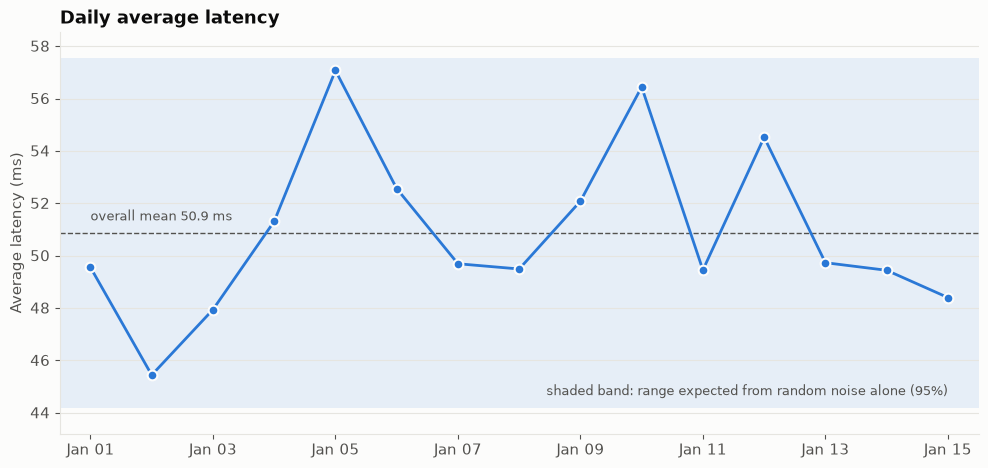

Noise band: 44.2 - 57.5 ms (typical day has 23 observations)
Days outside the band: 0 of 15



In [ ]:
# Chart 1 - Daily average latency
import matplotlib.dates as mdates

daily = daily_latency.copy()
daily["observation_date"] = pd.to_datetime(daily["observation_date"])

overall_mean = df_clean["latency_ms"].mean()
overall_sd = df_clean["latency_ms"].std()
typical_n = daily["observations"].median()
half_width = 1.96 * overall_sd / np.sqrt(typical_n)     # range expected from random noise alone
lo, hi = overall_mean - half_width, overall_mean + half_width
outside = daily[(daily["daily_latency_ms"] < lo) | (daily["daily_latency_ms"] > hi)]

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.axhspan(lo, hi, color=BLUE, alpha=0.10, lw=0)
ax.axhline(overall_mean, color=MUTED, lw=1, ls="--")
ax.plot(daily["observation_date"], daily["daily_latency_ms"], color=BLUE, lw=2,
        marker="o", ms=7, mfc=BLUE, mec=SURFACE, mew=1.5)

x_start, x_end = daily["observation_date"].iloc[0], daily["observation_date"].iloc[-1]
ax.text(x_start, overall_mean + 0.35, f"overall mean {overall_mean:.1f} ms", va="bottom", ha="left",
        color=MUTED, fontsize=9.5)
ax.text(x_end, lo + 0.35, "shaded band: range expected from random noise alone (95%)",
        va="bottom", ha="right", color=MUTED, fontsize=9.5)
ax.set_title("Daily average latency")
ax.set_ylabel("Average latency (ms)")
ax.set_xlabel("")
ax.set_xlim(x_start - pd.Timedelta(hours=12), x_end + pd.Timedelta(hours=12))
ax.set_ylim(lo - 1, hi + 1)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
fig.tight_layout()
save_fig(fig, "daily_latency.png")
plt.show()

print(f"Noise band: {lo:.1f} - {hi:.1f} ms (typical day has {typical_n:.0f} observations)")
print(f"Days outside the band: {len(outside)} of {len(daily)}")
print(outside.to_string(index=False) if len(outside) else "")

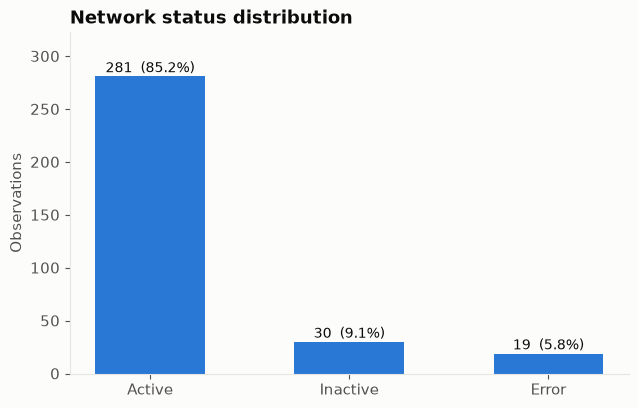

In [12]:
# Chart 2 - Status distribution (from the SQL result)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
bars = ax.bar(status_summary["status"], status_summary["record_count"], color=BLUE, width=0.55)
for bar, n, pct in zip(bars, status_summary["record_count"], status_summary["percentage"]):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 4, f"{n}  ({pct:.1f}%)", ha="center", color=INK, fontsize=10)
ax.set_ylim(0, status_summary["record_count"].max() * 1.15)
ax.set_title("Network status distribution")
ax.set_xlabel("")
ax.set_ylabel("Observations")
ax.grid(False)
fig.tight_layout()
save_fig(fig, "status_distribution.png")
plt.show()

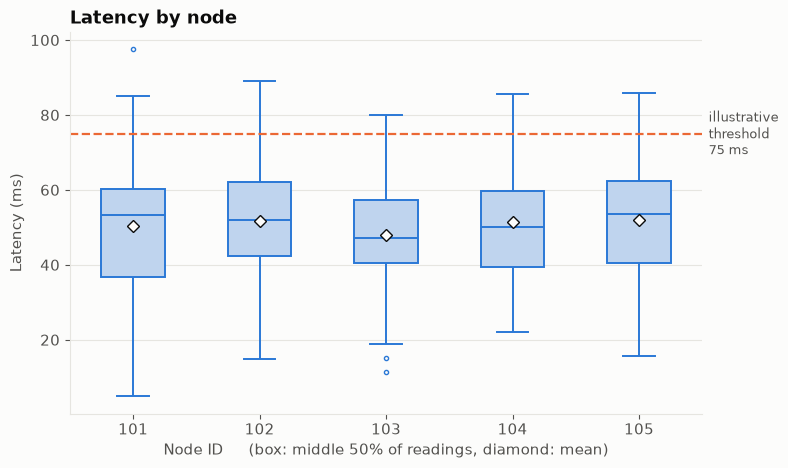

In [13]:
# Chart 3 - Latency by node (distribution, not just the mean)
order = [str(n) for n in sorted(df_clean["node_id"].unique())]
plot_df = df_clean.assign(node=df_clean["node_id"].astype(str))

fig, ax = plt.subplots(figsize=(8, 4.8))
sns.boxplot(data=plot_df, x="node", y="latency_ms", order=order, color="#b7d3f6", linecolor=BLUE,
            linewidth=1.4, width=0.5, fliersize=3, showmeans=True,
            meanprops=dict(marker="D", markerfacecolor=SURFACE, markeredgecolor=INK, markersize=6), ax=ax)
ax.axhline(LATENCY_SLA_MS, color=ORANGE, lw=1.6, ls="--")
ax.text(1.01, LATENCY_SLA_MS, f"illustrative\nthreshold\n{LATENCY_SLA_MS} ms", transform=ax.get_yaxis_transform(),
        ha="left", va="center", color=MUTED, fontsize=9.5)
ax.set_title("Latency by node")
ax.set_xlabel("Node ID     (box: middle 50% of readings, diamond: mean)")
ax.set_ylabel("Latency (ms)")
fig.tight_layout()
save_fig(fig, "latency_by_node.png")
plt.show()

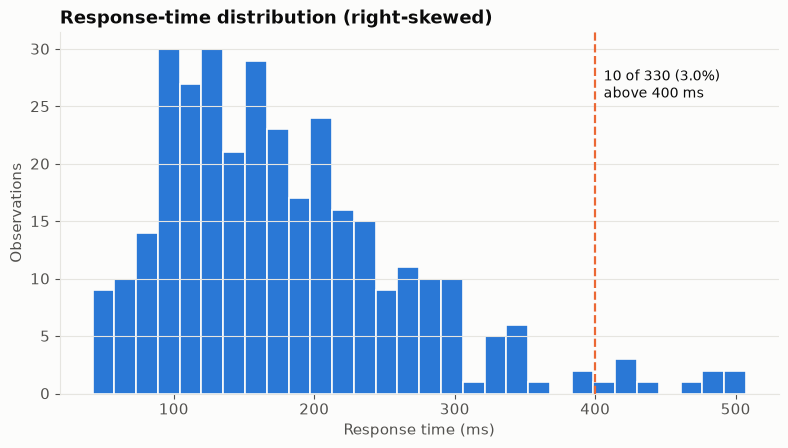

In [14]:
# Chart 4 - Response-time distribution
n_slow = int(df_clean["response_breach"].sum())
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.hist(df_clean["response_time_ms"], bins=30, color=BLUE, edgecolor=SURFACE, linewidth=1.2)
ax.axvline(RESPONSE_SLA_MS, color=ORANGE, lw=1.6, ls="--")
ax.text(RESPONSE_SLA_MS + 6, ax.get_ylim()[1] * 0.9,
        f"{n_slow} of {len(df_clean)} ({n_slow / len(df_clean):.1%})\nabove {RESPONSE_SLA_MS} ms",
        color=INK, fontsize=10, va="top")
ax.set_title("Response-time distribution (right-skewed)")
ax.set_xlabel("Response time (ms)")
ax.set_ylabel("Observations")
ax.grid(axis="x", visible=False)
fig.tight_layout()
save_fig(fig, "response_time_distribution.png")
plt.show()

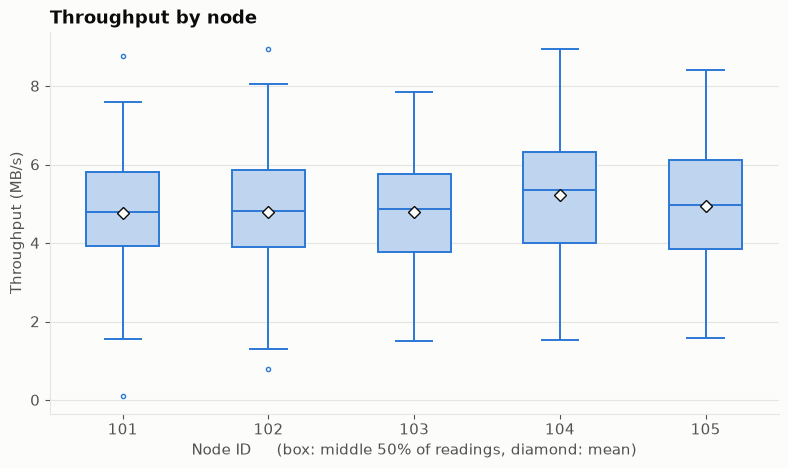

In [15]:
# Chart 5 - Throughput by node
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.boxplot(data=plot_df, x="node", y="throughput_MBps", order=order, color="#b7d3f6", linecolor=BLUE,
            linewidth=1.4, width=0.5, fliersize=3, showmeans=True,
            meanprops=dict(marker="D", markerfacecolor=SURFACE, markeredgecolor=INK, markersize=6), ax=ax)
ax.set_title("Throughput by node")
ax.set_xlabel("Node ID     (box: middle 50% of readings, diamond: mean)")
ax.set_ylabel("Throughput (MB/s)")
fig.tight_layout()
save_fig(fig, "throughput_by_node.png")
plt.show()

## 8. Findings from the data above.

In [16]:
hi_node = node_summary.loc[node_summary["avg_latency_ms"].idxmax()]
lo_node = node_summary.loc[node_summary["avg_latency_ms"].idxmin()]
gap = hi_node["avg_latency_ms"] - lo_node["avg_latency_ms"]
kw_latency_p = tests.loc[tests["comparison"] == "latency_ms by node", "p_value"].iloc[0]

print(f"Availability: {kpis.loc[1, 'Value']}%  |  Error rate: {kpis.loc[3, 'Value']}%")
print(f"Latency: avg {kpis.loc[4, 'Value']} ms, p95 {kpis.loc[5, 'Value']} ms")
print(f"Response time: avg {kpis.loc[6, 'Value']} ms, p95 {kpis.loc[7, 'Value']} ms; "
      f"{n_slow} observations above {RESPONSE_SLA_MS} ms")
print(f"Throughput: avg {kpis.loc[8, 'Value']} MB/s")
print()
print(f"Highest average latency: node {int(hi_node['node_id'])} ({hi_node['avg_latency_ms']} ms)")
print(f"Lowest average latency : node {int(lo_node['node_id'])} ({lo_node['avg_latency_ms']} ms)")
print(f"Gap between them       : {gap:.2f} ms, compared with a latency standard deviation of {overall_sd:.1f} ms")
print(f"Kruskal-Wallis p-value for latency across nodes: {kw_latency_p}")
print("Significant node differences:", tests.loc[tests["significant_at_5pct"], "comparison"].tolist() or "none")

Availability: 85.15%  |  Error rate: 5.76%
Latency: avg 50.87 ms, p95 78.63 ms
Response time: avg 180.2 ms, p95 339.87 ms; 10 observations above 400 ms
Throughput: avg 4.91 MB/s

Highest average latency: node 105 (52.09 ms)
Lowest average latency : node 103 (47.99 ms)
Gap between them       : 4.10 ms, compared with a latency standard deviation of 16.3 ms
Kruskal-Wallis p-value for latency across nodes: 0.646
Significant node differences: none


## 9. Conclusions

**Overall health.** Over the 15 days, 85.15% of observations were `Active`, 9.09% `Inactive` and 5.76% `Error`. Latency averaged 50.87 ms (p95 78.63 ms); response time averaged 180.20 ms (p95 339.87 ms), with 10 of 330 observations (3.0%) above the 400 ms threshold; throughput averaged 4.91 MB/s.

**Nodes look different, but the differences are not statistically meaningful.**

- Node 105 has the highest average latency (52.09 ms) and node 103 the lowest (47.99 ms). The 4.10 ms gap is small next to a latency standard deviation of about 16 ms, and the Kruskal-Wallis test gives p = 0.646.
- Nodes 105 and 104 show the highest error rates (8.5% and 7.5% versus 3.5-4.5% elsewhere), and node 103 the lowest availability (80.7%). With only 2-6 error records per node this is easily chance: the chi-square test gives p = 0.582 (and its expected counts are small, so it is approximate).
- Throughput and response time also show no significant difference between nodes (p = 0.501 and p = 0.570), and `Error` records do not have significantly different latency from `Active` ones (p = 0.116).

**Time pattern.** Daily average latency moves between about 45 and 57 ms, but every day falls inside the range expected from random variation alone, so there is no evidence of a trend or a degraded period.

**How to read this.** The dataset was generated with every column drawn independently, so "no significant structure" is exactly what we should find. The value of this notebook is the workflow - validation, flagging, SQL summaries, KPIs, significance testing and honest charts - rather than any claim about a real network. With real telemetry the same code would be pointed at data where node-level problems, time-of-day effects, or errors that coincide with high latency could actually appear.

**Next steps.**

- Regenerate the data with node-specific latency baselines, errors that correlate with high latency, and a deliberately degraded period, then check that this analysis detects them.
- Add per-node daily or hourly KPIs and an anomaly flag (for example, rolling mean plus 3 standard deviations).
- Wrap the KPIs and charts in a Streamlit dashboard.


In [17]:
conn.close()